In [1]:
# Put the repository root on sys.path, wherever the kernel was started from.
import os, sys

def _find_repo_root():
    _pkgs = ("genotyping", "pipelines", "screening", "sequencing")
    for _cand in [os.getcwd(), *sys.path]:
        if not _cand:
            continue
        _d = os.path.abspath(_cand)
        while True:
            if all(os.path.isdir(os.path.join(_d, _p)) for _p in _pkgs):
                return _d
            _parent = os.path.dirname(_d)
            if _parent == _d:
                break
            _d = _parent
    return None

_repo_root = _find_repo_root()
if _repo_root and _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import A14_03_config as config
from pathlib import Path
import sys
import os
import multiprocessing as mp
import importlib

import pandas as pd
import os
# import seaborn as sns
import matplotlib.pyplot as plt

from pipelines import common_tasks

# Reload the modules
importlib.reload(config)
importlib.reload(common_tasks)

from screening import screen_utils

NAS_folder = "/mnt/G_Pharma/Users/tfang/Cell_Screen/PW_A14-03_Screen/output_transfered"
os.makedirs(NAS_folder, exist_ok=True)

In [2]:
def reverse_complement(seq):
    complement = {'A': 'T', 'T': 'A', 'C': 'G', 'G': 'C'}
    return ''.join(complement[base] for base in reversed(seq))

lib=config.get_library()
lib["Random_filler_10bp_rc"]=lib["oligofinal"].str[126:126+10]
lib["Random_filler_10bp"]=lib["Random_filler_10bp_rc"].apply(lambda x: reverse_complement(x))
# https://www.nature.com/articles/s41586-021-04058-1: run-off sequencing of the cleavage products confirmed a staggered cleavage pattern at 15–21 bp from the TAM that resulted in 5′ overhangs (Fig. 2g).
lib["tnpb_window"]=lib["target_site"].str[15-10:]+ lib["Random_filler_10bp"].str[0:5] # left and right 10bp around tnpb cut sites,
lib

,Unnamed: 0,finalname,lib_section,specific_primerpart,barcode,spacer,target rv,oligofinal,llength,barcode_verified,target_site_rc_PlusTAM,target_site_PlusTAM,target_site,TAM,Random_filler_10bp_rc,Random_filler_10bp,tnpb_window
0,NaN,LIB_A14-01,LIB-A14-01,NaN,GCACGTA,TTCCAGTTAAGGAGAGGAAT,ATTCCTCTCCTTAACTGGAAATCTT,CGCGACTTTAGTCGTGTGAGGTTCAATTCCAGTTAAGGAGAGGAAT...,209,GCACGTA,ATTCCTCTCCTTAACTGGAAATCTT,AAGATTTCCAGTTAAGGAGAGGAAT,TTCCAGTTAAGGAGAGGAAT,AAGAT,GGCAGCCGCC,GGCGGCTGCC,GTTAAGGAGAGGAATGGCGG
1,NaN,LIB_A14-01,LIB-A14-01,NaN,CGACGTC,TGAAAACTTCAGTGATATCG,CGATATCACTGAAGTTTTCAATCTT,CGCGACTTTAGTCGTGTGAGGTTCAATGAAAACTTCAGTGATATCG...,209,CGACGTC,CGATATCACTGAAGTTTTCAATCTT,AAGATTGAAAACTTCAGTGATATCG,TGAAAACTTCAGTGATATCG,AAGAT,GGCAGCCGCC,GGCGGCTGCC,ACTTCAGTGATATCGGGCGG
2,NaN,LIB_A14-01,LIB-A14-01,NaN,GATGTTC,GGCAGAAGGTACACAGCAAC,GTTGCTGTGTACCTTCTGCCATCTT,CGCGACTTTAGTCGTGTGAGGTTCAAGGCAGAAGGTACACAGCAAC...,209,GATGTTC,GTTGCTGTGTACCTTCTGCCATCTT,AAGATGGCAGAAGGTACACAGCAAC,GGCAGAAGGTACACAGCAAC,AAGAT,GGCAGCCGCC,GGCGGCTGCC,AAGGTACACAGCAACGGCGG
3,NaN,LIB_A14-01,LIB-A14-01,NaN,AGGAAAT,TATAGTTAAAAATATGCCAC,GTGGCATATTTTTAACTATAATCTT,CGCGACTTTAGTCGTGTGAGGTTCAATATAGTTAAAAATATGCCAC...,209,AGGAAAT,GTGGCATATTTTTAACTATAATCTT,AAGATTATAGTTAAAAATATGCCAC,TATAGTTAAAAATATGCCAC,AAGAT,GGCAGCCGCC,GGCGGCTGCC,TTAAAAATATGCCACGGCGG
4,NaN,LIB_A14-01,LIB-A14-01,NaN,GTCGCCT,AAGGAGATTATACCCAGAAT,ATTCTGGGTATAATCTCCTTATCTT,CGCGACTTTAGTCGTGTGAGGTTCAAAAGGAGATTATACCCAGAAT...,209,GTCGCCT,ATTCTGGGTATAATCTCCTTATCTT,AAGATAAGGAGATTATACCCAGAAT,AAGGAGATTATACCCAGAAT,AAGAT,GGCAGCCGCC,GGCGGCTGCC,GATTATACCCAGAATGGCGG
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
479,NaN,LIB_A14-01,LIB-A14-01,NaN,GTGACTT,TTAGGTAAATAAAGATCTCT,AGAGATCTTTATTTACCTAACTCAA,CGCGACTTTAGTCGTGTGAGGTTCAATTAGGTAAATAAAGATCTCT...,209,GTGACTT,AGAGATCTTTATTTACCTAACTCAA,TTGAGTTAGGTAAATAAAGATCTCT,TTAGGTAAATAAAGATCTCT,TTGAG,GGCAGCCGCC,GGCGGCTGCC,TAAATAAAGATCTCTGGCGG
480,NaN,LIB_A14-01,LIB-A14-01,NaN,TGTCCTA,TTCTACTCAAGCCGCTCTAC,GTAGAGCGGCTTGAGTAGAACTCAA,CGCGACTTTAGTCGTGTGAGGTTCAATTCTACTCAAGCCGCTCTAC...,209,TGTCCTA,GTAGAGCGGCTTGAGTAGAACTCAA,TTGAGTTCTACTCAAGCCGCTCTAC,TTCTACTCAAGCCGCTCTAC,TTGAG,GGCAGCCGCC,GGCGGCTGCC,CTCAAGCCGCTCTACGGCGG
481,NaN,LIB_A14-01,LIB-A14-01,NaN,GCAACCA,GAAGAGGACCTGGGAGATGA,TCATCTCCCAGGTCCTCTTCCTCAA,CGCGACTTTAGTCGTGTGAGGTTCAAGAAGAGGACCTGGGAGATGA...,209,GCAACCA,TCATCTCCCAGGTCCTCTTCCTCAA,TTGAGGAAGAGGACCTGGGAGATGA,GAAGAGGACCTGGGAGATGA,TTGAG,GGCAGCCGCC,GGCGGCTGCC,GGACCTGGGAGATGAGGCGG
482,NaN,LIB_A14-01,LIB-A14-01,NaN,GGTAACG,TATTATATATGAGTTCACTG,CAGTGAACTCATATATAATACTCAA,CGCGACTTTAGTCGTGTGAGGTTCAATATTATATATGAGTTCACTG...,209,GGTAACG,CAGTGAACTCATATATAATACTCAA,TTGAGTATTATATATGAGTTCACTG,TATTATATATGAGTTCACTG,TTGAG,GGCAGCCGCC,GGCGGCTGCC,TATATGAGTTCACTGGGCGG


In [3]:
samples= config.get_samples()
print(samples.shape)
indel_samples=config.get_indel_samples()
print(indel_samples.shape)
indel_samples

(36, 10)
(21, 10)


,sample_name,sequencing_name,bioreplicate,replicate,file_name_R1,file_name_R2,editor,is_ctrl,lib_section,edit_type
15,A14-03_Sample-16_Mock_LIB-A14-01_rep1,Sample-16,Mock_LIB-A14-01,1,Sample-16_S16_L001_R1_001.fastq.gz,Sample-16_S16_L001_R2_001.fastq.gz,NOEDITOR,yes,LIB-A14-01,Mock
16,A14-03_Sample-18_TnpB-WT_nuclease_LIB-A14-01_rep1,Sample-18,TnpB-WT_nuclease_LIB-A14-01,1,Sample-18_S17_L001_R1_001.fastq.gz,Sample-18_S17_L001_R2_001.fastq.gz,TnpB-WT_nuclease,no,LIB-A14-01,INDEL
17,A14-03_Sample-19_TnpB-pPW222_nuclease_LIB-A14-...,Sample-19,TnpB-pPW222_nuclease_LIB-A14-01,1,Sample-19_S18_L001_R1_001.fastq.gz,Sample-19_S18_L001_R2_001.fastq.gz,TnpB-pPW222_nuclease,no,LIB-A14-01,INDEL
18,A14-03_Sample-20_TnpB-pPW226_nuclease_LIB-A14-...,Sample-20,TnpB-pPW226_nuclease_LIB-A14-01,1,Sample-20_S19_L001_R1_001.fastq.gz,Sample-20_S19_L001_R2_001.fastq.gz,TnpB-pPW226_nuclease,no,LIB-A14-01,INDEL
19,A14-03_Sample-21_TnpB-pPW258_nuclease_LIB-A14-...,Sample-21,TnpB-pPW258_nuclease_LIB-A14-01,1,Sample-21_S20_L001_R1_001.fastq.gz,Sample-21_S20_L001_R2_001.fastq.gz,TnpB-pPW258_nuclease,no,LIB-A14-01,INDEL
20,A14-03_Sample-22_TnpB-pPW259_nuclease_LIB-A14-...,Sample-22,TnpB-pPW259_nuclease_LIB-A14-01,1,Sample-22_S21_L001_R1_001.fastq.gz,Sample-22_S21_L001_R2_001.fastq.gz,TnpB-pPW259_nuclease,no,LIB-A14-01,INDEL
21,A14-03_Sample-23_TnpB-pPW260_nuclease_LIB-A14-...,Sample-23,TnpB-pPW260_nuclease_LIB-A14-01,1,Sample-23_S22_L001_R1_001.fastq.gz,Sample-23_S22_L001_R2_001.fastq.gz,TnpB-pPW260_nuclease,no,LIB-A14-01,INDEL
22,A14-03_Sample-30_TnpB-WT_nuclease_LIB-A14-01_rep2,Sample-30,TnpB-WT_nuclease_LIB-A14-01,2,Sample-30_S23_L001_R1_001.fastq.gz,Sample-30_S23_L001_R2_001.fastq.gz,TnpB-WT_nuclease,no,LIB-A14-01,INDEL
23,A14-03_Sample-31_TnpB-pPW222_nuclease_LIB-A14-...,Sample-31,TnpB-pPW222_nuclease_LIB-A14-01,2,Sample-31_S24_L001_R1_001.fastq.gz,Sample-31_S24_L001_R2_001.fastq.gz,TnpB-pPW222_nuclease,no,LIB-A14-01,INDEL
24,A14-03_Sample-32_TnpB-pPW226_nuclease_LIB-A14-...,Sample-32,TnpB-pPW226_nuclease_LIB-A14-01,2,Sample-32_S25_L001_R1_001.fastq.gz,Sample-32_S25_L001_R2_001.fastq.gz,TnpB-pPW226_nuclease,no,LIB-A14-01,INDEL


# analysis of the results

In [4]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import A14_03_config as config
import pandas as pd
import numpy as np
import os
import sys

import os, sys
_repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

from screening import screen_utils

# import A13_config as config

# import sys
# import os
# import multiprocessing as mp
import importlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# import os, sys
_repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

# # Reload the modules
importlib.reload(config)
importlib.reload(screen_utils)
# importlib.reload(common_tasks)

<module 'screening.screen_utils' from '/home/tao/code/tnpb-analysis/screening/screen_utils.py'>

In [5]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

def check_A_to_A_or_C(df):
    df['valid_diff_nt'] = df.apply(lambda row: sum(tsl == ts or (tsl == 'A' and ts in ['C', 'G']) for tsl, ts in zip(row['target_site_lib'], row['most_common_diff_target_site'])) if pd.notna(row['most_common_diff_target_site']) else 20, axis=1)
    return df

# check come quality stats

In [6]:
import pandas as pd
from pathlib import Path

pd.set_option('display.max_colwidth', 100)  # Show all columns in the output

## check reads level quality

In [7]:
def collect_indel_read_edit_rates(config,sample_name_column='sample_name',editor_column='editor',control_column='control_yes_no'):
    """ Collect edit rates for all samples"""
    print('Collecting Indel edit rates for all samples')
    samples=config.get_indel_samples()
    all_sample_rates = pd.concat(
        [
            pd.read_csv(config.edit_rate(f'{sample[sample_name_column]}-reads-indelrates-unfiltered'), index_col=0).assign(
                editor=sample[editor_column],
                sample_name=sample[sample_name_column],
                is_ctrl=sample[control_column],
                replicate=sample["replicate"],
            )
            for _,sample in samples.iterrows()
        ]
    ).reset_index(drop=True)
    all_sample_rates.loc[:, 'is_ctrl'] = all_sample_rates.is_ctrl == 'yes'
    return all_sample_rates
    #all_sample_rates.to_csv(config.edit_rate('all-abe-samples-reads-editedrates-unfiltered-not-normalized'))
    

In [8]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_indel_samples_reads_indeldrates_unfiltered_not_normalized=collect_indel_read_edit_rates(config,sample_name_column='sample_name',
                                                                                        editor_column='editor',control_column="is_ctrl")
print(all_indel_samples_reads_indeldrates_unfiltered_not_normalized.shape)

all_indel_samples_reads_indeldrates_unfiltered_not_normalized.head(n=3)

(9899, 16)


,barcode,spacer,TAM,frac_reads_edited,num_reads,Random_filler_10bp_rc,target_site,target_site_lib,Random_filler_10bp,tnpb_window,Random_filler_10bp_lib,tnpb_window_lib,editor,sample_name,is_ctrl,replicate
0,AAAAATA,TTCTTTGAGACTTGGCATGC,GGGAT,0.0,66,GGCAGCCGCC,TTCTTTGAGACTCGGCATGC,TTCTTTGAGACTTGGCATGC,GGCGGCTGCC,TGAGACTCGGCATGCGGCGG,GGCGGCTGCC,TGAGACTTGGCATGCGGCGG,NOEDITOR,A14-03_Sample-16_Mock_LIB-A14-01_rep1,True,1
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.0,137,GGCAGCCGCC,CTAAAGAAAAATTCCTTGCC,TTAAAGAAAAATTCCTTGCC,GGCGGCTGCC,GAAAAATTCCTTGCCGGCGG,GGCGGCTGCC,GAAAAATTCCTTGCCGGCGG,NOEDITOR,A14-03_Sample-16_Mock_LIB-A14-01_rep1,True,1
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.0,975,GGCAACCGCC,CTAAGAAGTTATACTCTTTC,CTAAGAAGTTATACTCTTTC,GGCGGTTGCC,AAGTTATACTCTTTCGGCGG,GGCGGCTGCC,AAGTTATACTCTTTCGGCGG,NOEDITOR,A14-03_Sample-16_Mock_LIB-A14-01_rep1,True,1


In [9]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_indel_samples_reads_indeldrates_unfiltered_not_normalized=all_indel_samples_reads_indeldrates_unfiltered_not_normalized.merge(samples[['sample_name','bioreplicate','lib_section']],on='sample_name', how='left',
                                                                     )
all_indel_samples_reads_indeldrates_unfiltered_not_normalized["sample_name"] = all_indel_samples_reads_indeldrates_unfiltered_not_normalized["sample_name"].str.split("Sample-").str[-1]
all_indel_samples_reads_indeldrates_unfiltered_not_normalized["sample_name"] = all_indel_samples_reads_indeldrates_unfiltered_not_normalized["sample_name"].apply(lambda x: "_".join(x.split("_")[1:]))
print(all_indel_samples_reads_indeldrates_unfiltered_not_normalized.shape)
all_indel_samples_reads_indeldrates_unfiltered_not_normalized.head(n=3)

(9899, 18)


,barcode,spacer,TAM,frac_reads_edited,num_reads,Random_filler_10bp_rc,target_site,target_site_lib,Random_filler_10bp,tnpb_window,Random_filler_10bp_lib,tnpb_window_lib,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section
0,AAAAATA,TTCTTTGAGACTTGGCATGC,GGGAT,0.0,66,GGCAGCCGCC,TTCTTTGAGACTCGGCATGC,TTCTTTGAGACTTGGCATGC,GGCGGCTGCC,TGAGACTCGGCATGCGGCGG,GGCGGCTGCC,TGAGACTTGGCATGCGGCGG,NOEDITOR,Mock_LIB-A14-01_rep1,True,1,Mock_LIB-A14-01,LIB-A14-01
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.0,137,GGCAGCCGCC,CTAAAGAAAAATTCCTTGCC,TTAAAGAAAAATTCCTTGCC,GGCGGCTGCC,GAAAAATTCCTTGCCGGCGG,GGCGGCTGCC,GAAAAATTCCTTGCCGGCGG,NOEDITOR,Mock_LIB-A14-01_rep1,True,1,Mock_LIB-A14-01,LIB-A14-01
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.0,975,GGCAACCGCC,CTAAGAAGTTATACTCTTTC,CTAAGAAGTTATACTCTTTC,GGCGGTTGCC,AAGTTATACTCTTTCGGCGG,GGCGGCTGCC,AAGTTATACTCTTTCGGCGG,NOEDITOR,Mock_LIB-A14-01_rep1,True,1,Mock_LIB-A14-01,LIB-A14-01


In [10]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_indel_samples_reads_indeldrates_unfiltered_not_normalized=all_indel_samples_reads_indeldrates_unfiltered_not_normalized.merge(lib[['barcode','spacer']], on='barcode', how='left',suffixes=('', '_LIB'))
print(all_indel_samples_reads_indeldrates_unfiltered_not_normalized.shape)
all_indel_samples_reads_indeldrates_unfiltered_not_normalized.head(n=3)

(9899, 19)


,barcode,spacer,TAM,frac_reads_edited,num_reads,Random_filler_10bp_rc,target_site,target_site_lib,Random_filler_10bp,tnpb_window,Random_filler_10bp_lib,tnpb_window_lib,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
0,AAAAATA,TTCTTTGAGACTTGGCATGC,GGGAT,0.0,66,GGCAGCCGCC,TTCTTTGAGACTCGGCATGC,TTCTTTGAGACTTGGCATGC,GGCGGCTGCC,TGAGACTCGGCATGCGGCGG,GGCGGCTGCC,TGAGACTTGGCATGCGGCGG,NOEDITOR,Mock_LIB-A14-01_rep1,True,1,Mock_LIB-A14-01,LIB-A14-01,TTCTTTGAGACTTGGCATGC
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.0,137,GGCAGCCGCC,CTAAAGAAAAATTCCTTGCC,TTAAAGAAAAATTCCTTGCC,GGCGGCTGCC,GAAAAATTCCTTGCCGGCGG,GGCGGCTGCC,GAAAAATTCCTTGCCGGCGG,NOEDITOR,Mock_LIB-A14-01_rep1,True,1,Mock_LIB-A14-01,LIB-A14-01,TTAAAGAAAAATTCCTTGCC
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.0,975,GGCAACCGCC,CTAAGAAGTTATACTCTTTC,CTAAGAAGTTATACTCTTTC,GGCGGTTGCC,AAGTTATACTCTTTCGGCGG,GGCGGCTGCC,AAGTTATACTCTTTCGGCGG,NOEDITOR,Mock_LIB-A14-01_rep1,True,1,Mock_LIB-A14-01,LIB-A14-01,CTAAGAAGTTATACTCTTTC


In [11]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_indel_samples_reads_indeldrates_not_normalized=all_indel_samples_reads_indeldrates_unfiltered_not_normalized.\
    loc[all_indel_samples_reads_indeldrates_unfiltered_not_normalized['num_reads'] >= 100]     # 100,
print(all_indel_samples_reads_indeldrates_not_normalized.shape)
all_indel_samples_reads_indeldrates_not_normalized.head(n=3)

(8048, 19)


,barcode,spacer,TAM,frac_reads_edited,num_reads,Random_filler_10bp_rc,target_site,target_site_lib,Random_filler_10bp,tnpb_window,Random_filler_10bp_lib,tnpb_window_lib,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.000000,137,GGCAGCCGCC,CTAAAGAAAAATTCCTTGCC,TTAAAGAAAAATTCCTTGCC,GGCGGCTGCC,GAAAAATTCCTTGCCGGCGG,GGCGGCTGCC,GAAAAATTCCTTGCCGGCGG,NOEDITOR,Mock_LIB-A14-01_rep1,True,1,Mock_LIB-A14-01,LIB-A14-01,TTAAAGAAAAATTCCTTGCC
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.000000,975,GGCAACCGCC,CTAAGAAGTTATACTCTTTC,CTAAGAAGTTATACTCTTTC,GGCGGTTGCC,AAGTTATACTCTTTCGGCGG,GGCGGCTGCC,AAGTTATACTCTTTCGGCGG,NOEDITOR,Mock_LIB-A14-01_rep1,True,1,Mock_LIB-A14-01,LIB-A14-01,CTAAGAAGTTATACTCTTTC
3,AAACAAA,TATAGTTAAAAATATGCCAC,TTAAT,0.004219,237,GGCAGCCGCC,TACAGTTAAAAATATGCCAC,TATAGTTAAAAATATGCCAC,GGCGGCTGCC,TTAAAAATATGCCACGGCGG,GGCGGCTGCC,TTAAAAATATGCCACGGCGG,NOEDITOR,Mock_LIB-A14-01_rep1,True,1,Mock_LIB-A14-01,LIB-A14-01,TATAGTTAAAAATATGCCAC


In [12]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_indel_samples_reads_indeldrates_not_normalized_pivot_df = all_indel_samples_reads_indeldrates_not_normalized.pivot_table(index=['spacer', 'TAM', "target_site_lib"],
                                           columns='sample_name',
                                           values=['frac_reads_edited','num_reads'],  # values='edit_rate',
                                            aggfunc='first'
                                           ).reset_index()

all_indel_samples_reads_indeldrates_not_normalized_pivot_df.columns = ['_'.join(col).strip() for col in all_indel_samples_reads_indeldrates_not_normalized_pivot_df.columns.values]

print(all_indel_samples_reads_indeldrates_not_normalized_pivot_df.shape)
all_indel_samples_reads_indeldrates_not_normalized_pivot_df

(456, 45)


,spacer_,TAM_,target_site_lib_,frac_reads_edited_Mock_LIB-A14-01_rep1,frac_reads_edited_Mock_LIB-A14-01_rep2,frac_reads_edited_Mock_LIB-A14-01_rep3,frac_reads_edited_TnpB-WT_nuclease_LIB-A14-01_rep1,frac_reads_edited_TnpB-WT_nuclease_LIB-A14-01_rep2,frac_reads_edited_TnpB-WT_nuclease_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW222_nuclease_LIB-A14-01_rep1,...,num_reads_TnpB-pPW226_nuclease_LIB-A14-01_rep3,num_reads_TnpB-pPW258_nuclease_LIB-A14-01_rep1,num_reads_TnpB-pPW258_nuclease_LIB-A14-01_rep2,num_reads_TnpB-pPW258_nuclease_LIB-A14-01_rep3,num_reads_TnpB-pPW259_nuclease_LIB-A14-01_rep1,num_reads_TnpB-pPW259_nuclease_LIB-A14-01_rep2,num_reads_TnpB-pPW259_nuclease_LIB-A14-01_rep3,num_reads_TnpB-pPW260_nuclease_LIB-A14-01_rep1,num_reads_TnpB-pPW260_nuclease_LIB-A14-01_rep2,num_reads_TnpB-pPW260_nuclease_LIB-A14-01_rep3
0,AAGGAGATTATACCCAGAAT,AAGAT,AAGGAGATTATACCCAGAAT,0.002389,0.000750,0.000887,0.019093,0.041558,0.025547,0.012516,...,351.0,1470.0,885.0,330.0,973.0,1280.0,732.0,2372.0,131.0,209.0
1,AAGGAGATTATACCCAGAAT,ACGAT,AAGGAGATTATACCCAGAAT,0.001383,0.000000,0.000000,0.025916,0.022339,0.038994,0.015723,...,653.0,637.0,1356.0,1209.0,598.0,307.0,1425.0,871.0,122.0,819.0
2,AAGGAGATTATACCCAGAAT,AGGAT,AAGGAGATTATACCCAGAAT,0.017570,0.000756,0.005814,0.007080,0.027982,0.269333,0.004950,...,294.0,846.0,651.0,243.0,497.0,1324.0,1133.0,1855.0,791.0,496.0
3,AAGGAGATTATACCCAGAAT,ATGAT,AAGGAGATTATACCCAGAAT,0.008982,0.002647,0.002161,0.226644,0.595164,0.193426,0.430556,...,529.0,542.0,534.0,193.0,739.0,1095.0,485.0,673.0,686.0,476.0
4,AAGGAGATTATACCCAGAAT,CAGAT,AAGGAGATTATACCCAGAAT,0.001654,0.000657,0.011494,0.029260,0.008255,0.004847,0.017422,...,1071.0,414.0,145.0,531.0,1098.0,702.0,892.0,329.0,275.0,1058.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
451,TTCTTTGAGACTTGGCATGC,TTGAA,TTCTTTGAGACTTGGCATGC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,176.0,NaN,NaN,NaN,NaN,NaN
452,TTCTTTGAGACTTGGCATGC,TTGAC,TTCTTTGAGACTTGGCATGC,0.003546,0.001515,0.002869,0.069182,0.103718,0.056180,0.012766,...,224.0,208.0,355.0,360.0,229.0,NaN,114.0,112.0,812.0,1026.0
453,TTCTTTGAGACTTGGCATGC,TTGAG,TTCTTTGAGACTTGGCATGC,0.007273,0.000000,0.076389,0.018637,0.226054,0.003247,0.000000,...,178.0,285.0,535.0,165.0,431.0,526.0,999.0,NaN,117.0,621.0
454,TTCTTTGAGACTTGGCATGC,TTGAT,TTCTTTGAGACTTGGCATGC,0.000000,0.000000,0.004202,NaN,0.079812,0.063830,0.453988,...,NaN,435.0,247.0,141.0,190.0,107.0,721.0,144.0,216.0,NaN


In [13]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

editor_columns=sorted([l for l in all_indel_samples_reads_indeldrates_not_normalized_pivot_df.columns if "frac_reads" in l])

all_indel_samples_reads_indeldrates_not_normalized_pivot_df_slim=all_indel_samples_reads_indeldrates_not_normalized_pivot_df.loc[:,list(editor_columns)]
print(all_indel_samples_reads_indeldrates_not_normalized_pivot_df_slim.shape)
all_indel_samples_reads_indeldrates_not_normalized_pivot_df_slim

(456, 21)


,frac_reads_edited_Mock_LIB-A14-01_rep1,frac_reads_edited_Mock_LIB-A14-01_rep2,frac_reads_edited_Mock_LIB-A14-01_rep3,frac_reads_edited_TnpB-WT_nuclease_LIB-A14-01_rep1,frac_reads_edited_TnpB-WT_nuclease_LIB-A14-01_rep2,frac_reads_edited_TnpB-WT_nuclease_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW222_nuclease_LIB-A14-01_rep1,frac_reads_edited_TnpB-pPW222_nuclease_LIB-A14-01_rep2,frac_reads_edited_TnpB-pPW222_nuclease_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW226_nuclease_LIB-A14-01_rep1,...,frac_reads_edited_TnpB-pPW226_nuclease_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW258_nuclease_LIB-A14-01_rep1,frac_reads_edited_TnpB-pPW258_nuclease_LIB-A14-01_rep2,frac_reads_edited_TnpB-pPW258_nuclease_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW259_nuclease_LIB-A14-01_rep1,frac_reads_edited_TnpB-pPW259_nuclease_LIB-A14-01_rep2,frac_reads_edited_TnpB-pPW259_nuclease_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW260_nuclease_LIB-A14-01_rep1,frac_reads_edited_TnpB-pPW260_nuclease_LIB-A14-01_rep2,frac_reads_edited_TnpB-pPW260_nuclease_LIB-A14-01_rep3
0,0.002389,0.000750,0.000887,0.019093,0.041558,0.025547,0.012516,0.023055,0.010554,0.010802,...,0.193732,0.003401,0.004520,0.054545,0.010277,0.025781,0.043716,0.006324,0.022901,0.043062
1,0.001383,0.000000,0.000000,0.025916,0.022339,0.038994,0.015723,0.041667,0.211663,0.203762,...,0.009188,0.065934,0.017699,0.073615,0.008361,0.048860,0.014035,0.027555,0.155738,0.604396
2,0.017570,0.000756,0.005814,0.007080,0.027982,0.269333,0.004950,0.013699,0.277165,0.002191,...,0.010204,0.016548,0.012289,0.090535,0.010060,0.222054,0.007944,0.001617,0.007585,0.258065
3,0.008982,0.002647,0.002161,0.226644,0.595164,0.193426,0.430556,0.320856,0.282908,0.560091,...,0.202268,0.077491,0.473783,0.227979,0.051421,0.080365,0.230928,0.392273,0.364431,0.844538
4,0.001654,0.000657,0.011494,0.029260,0.008255,0.004847,0.017422,0.064935,0.148073,0.220612,...,0.036415,0.009662,0.013793,0.032015,0.336976,0.005698,0.014574,0.021277,0.447273,0.034972
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
451,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN
452,0.003546,0.001515,0.002869,0.069182,0.103718,0.056180,0.012766,0.007752,0.100000,0.015267,...,0.013393,0.014423,0.008451,0.877778,0.004367,NaN,0.000000,0.062500,0.070197,0.024366
453,0.007273,0.000000,0.076389,0.018637,0.226054,0.003247,0.000000,0.278388,0.014354,0.063425,...,0.000000,0.010526,0.003738,0.024242,0.018561,0.024715,0.014014,NaN,0.068376,0.012882
454,0.000000,0.000000,0.004202,NaN,0.079812,0.063830,0.453988,NaN,0.750000,0.071869,...,NaN,0.144828,0.753036,0.042553,0.005263,0.074766,0.006935,0.076389,0.685185,NaN


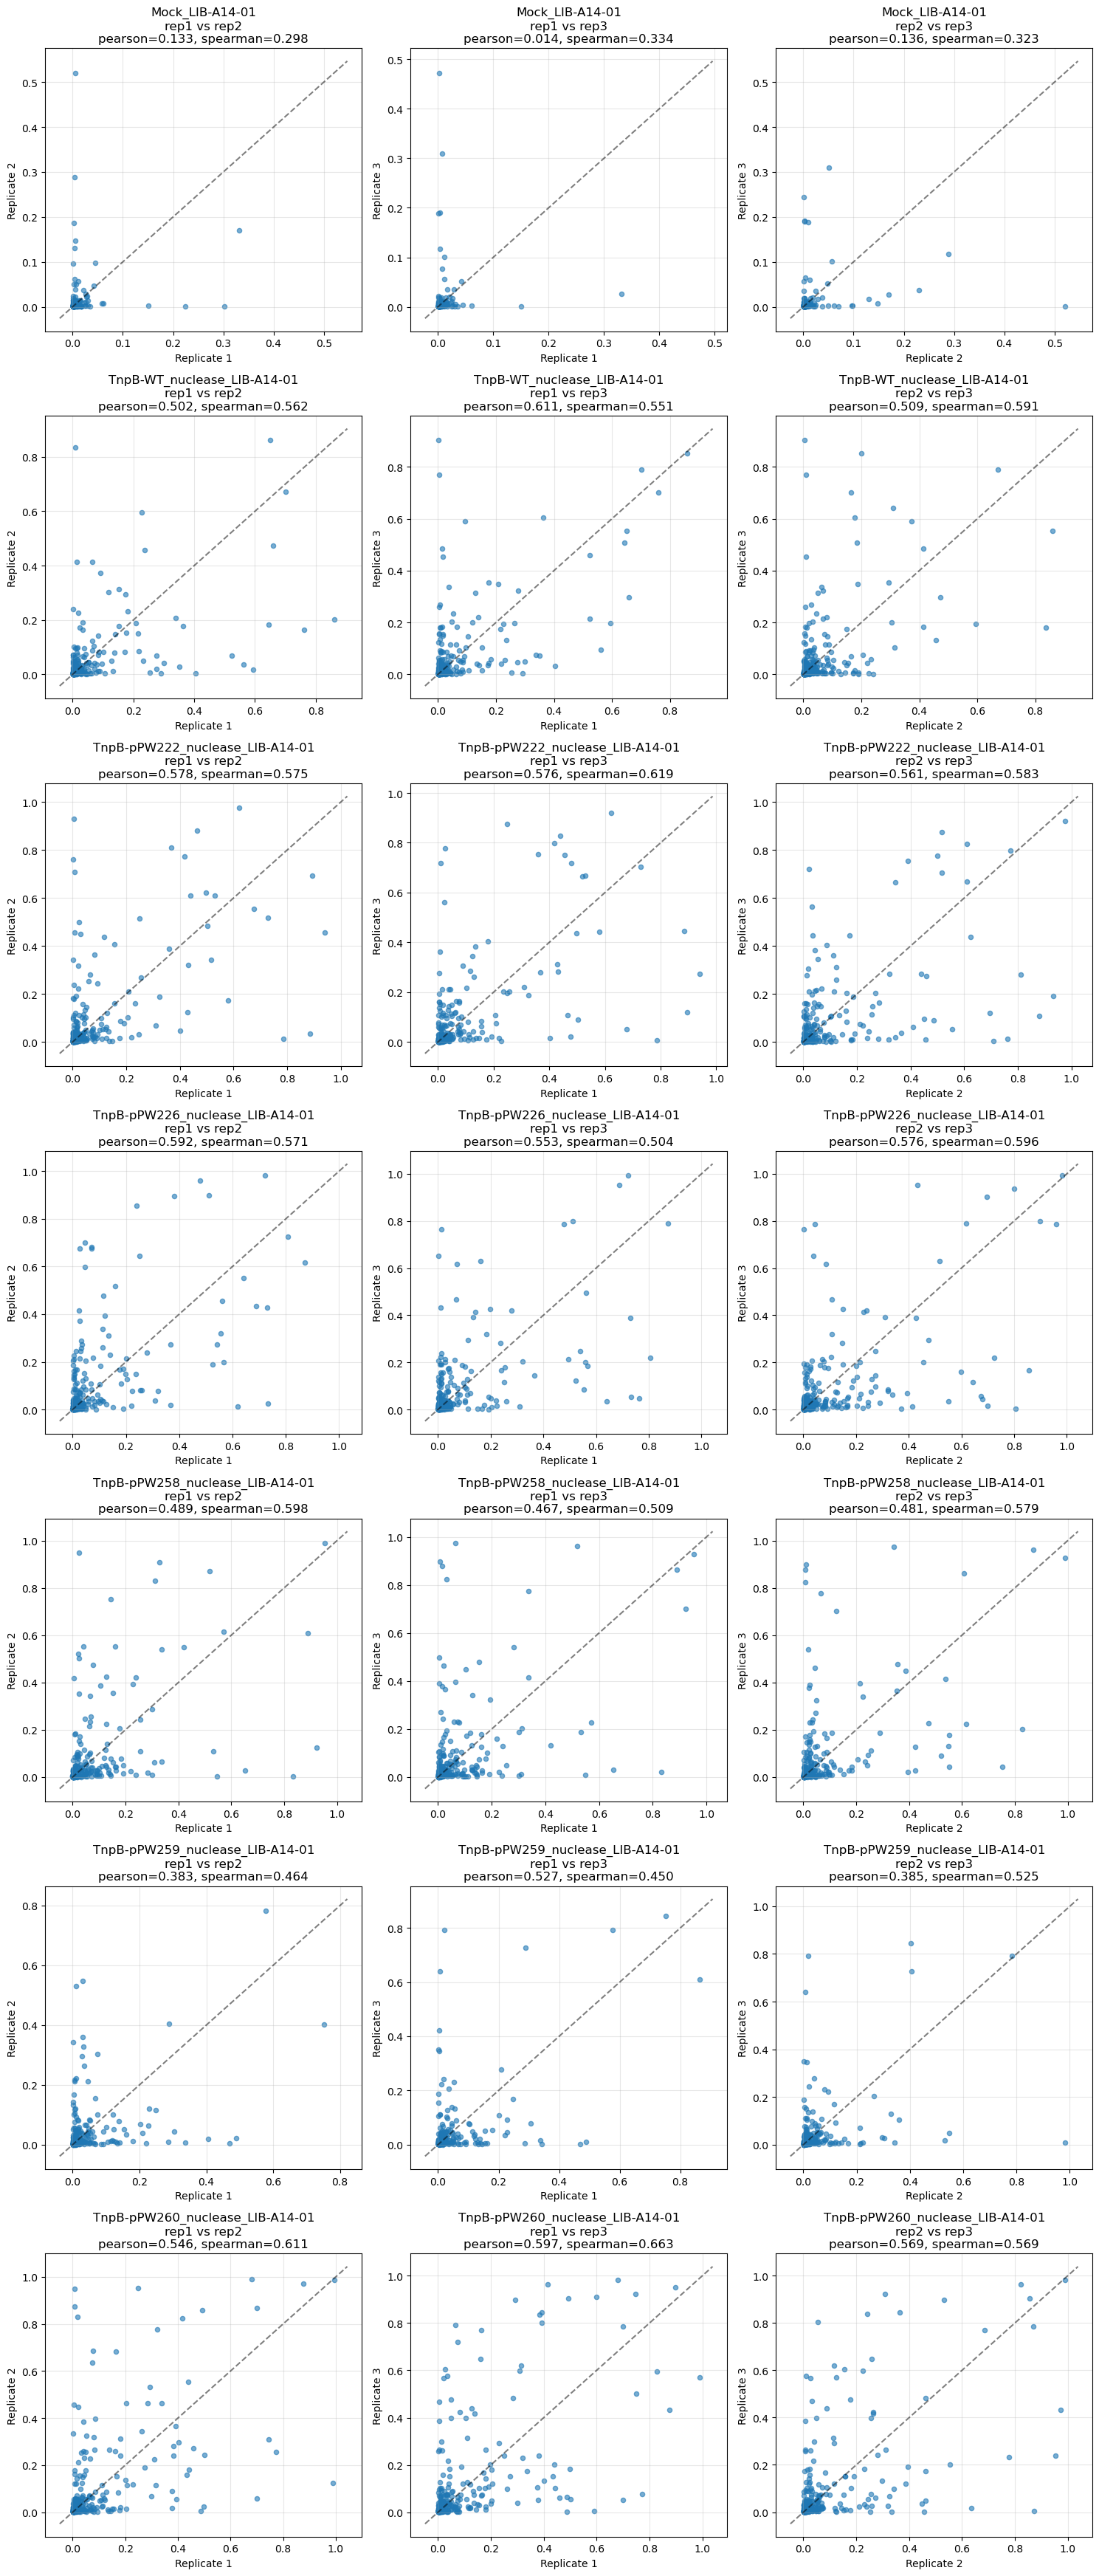

In [14]:
from scipy.stats import pearsonr, spearmanr

import matplotlib.pyplot as plt

def plot_paired_correlations(df,corr_edit_thres=0.3):
    """df have edit rate for different editor in different replicate, each column is one replice .
    column name are like this "frac_reads_edited_Mock_130_ABE_LIB-130_d10_rep1", "frac_reads_edited_Mock_130_ABE_LIB-130_d10_rep1"
    now i want to draw scatter plot between different replicates, for each editor, the plot in in row
    and show pearsonand spearman correlation in the figure legened

    for corr_edit_thres, only plot the replicates pair with correlation higher than this thres
    since editors have no/low editing for most of pams

    """
    # Extract editor names from column names
    editors = {}
    for col in df.columns:
        if col.startswith('frac_reads_edited_'):
            # Extract editor name (everything between 'frac_reads_edited_' and the last '_rep')
            editor_part = col.replace('frac_reads_edited_', '')
            editor_name = '_'.join(editor_part.split('_')[:-1])  # Remove the last _repX part
            if editor_name not in editors:
                editors[editor_name] = []
            editors[editor_name].append(col)

    # Create subplots - each row for one editor, columns for pairwise comparisons
    n_editors = len(editors)
    max_pairs = max(len(cols) * (len(cols) - 1) // 2 for cols in editors.values() if len(cols) > 1)

    fig, axes = plt.subplots(n_editors, max_pairs, figsize=(5*max_pairs, 5*n_editors))
    if n_editors == 1:
        axes = axes.reshape(1, -1)
    elif max_pairs == 1:
        axes = axes.reshape(-1, 1)

    for row_idx, (editor, columns) in enumerate(editors.items()):
        if len(columns) < 2:
            continue

        # Get all pairs of replicates
        pair_idx = 0
        for i in range(len(columns)):
            for j in range(i+1, len(columns)):
                col1, col2 = columns[i], columns[j]

                # Get data for correlation (remove NaN values)
                mask = ~(df[col1].isna() | df[col2].isna())
                x_data = df[col1][mask]
                y_data = df[col2][mask]

                #for x_data and y data. filter to get ones that both x_data and y_data > corr_edit_thres
                mask_corr_thres = (x_data > corr_edit_thres) & (y_data > corr_edit_thres) # (x_data > corr_edit_thres) | (y_data > corr_edit_thres)
                x_data = x_data[mask_corr_thres]
                y_data = y_data[mask_corr_thres]

                if len(x_data) > 0:
                    # Calculate correlations
                    pearson_r, pearson_p = pearsonr(x_data, y_data)
                    spearman_r, spearman_p = spearmanr(x_data, y_data)

                    # Plot scatter
                    ax = axes[row_idx, pair_idx]
                    ax.scatter(x_data, y_data, alpha=0.6, s=20)

                    # Extract replicate numbers
                    rep1 = col1.split('_rep')[-1]
                    rep2 = col2.split('_rep')[-1]

                    ax.set_xlabel(f'Replicate {rep1}')
                    ax.set_ylabel(f'Replicate {rep2}')
                    ax.set_title(f'{editor}\nrep{rep1} vs rep{rep2}\npearson={pearson_r:.3f}, spearman={spearman_r:.3f}')
                    ax.grid(True, alpha=0.3)

                    # Add diagonal line
                    max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
                    min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
                    ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)

                    pair_idx += 1

        # Hide unused subplots in this row
        for col_idx in range(pair_idx, max_pairs):
            axes[row_idx, col_idx].set_visible(False)

    plt.tight_layout()
    plt.show()

plot_paired_correlations(all_indel_samples_reads_indeldrates_not_normalized_pivot_df_slim,
                         corr_edit_thres=0.)

# here is correlatoin plot is meaningless, since most TAMs have low editing 

In [15]:
import seaborn as sns

def plot_heatmap_for_bioreplicate(mean_fracs, bioreplicate, vis_edit_thres=0.1, figsize=(8,6), cmap="viridis", save_figure=True, prefix="notNormalized"):

    # Filter for the specified bioreplicate and compute heatmap data
    df_heat = mean_fracs[mean_fracs["bioreplicate"] == bioreplicate].copy()
    df_heat.loc[df_heat['frac_reads_edited'] < vis_edit_thres, 'frac_reads_edited'] = 0
    # Check if all PAMs from config.PAMS are present in df_heat["TAM"]
    missing_pams = set(config.PAMS) - set(df_heat["TAM"].unique())
    if missing_pams:
        # For each missing PAM, add a row with frac_reads_edited set to 0
        df_missing = pd.DataFrame({'TAM': list(missing_pams), 'frac_reads_edited': 0})
        df_heat = pd.concat([df_heat, df_missing], ignore_index=True)
    df_heat["TAM_row"] = df_heat["TAM"].str[:2]
    df_heat["TAM_col"] = df_heat["TAM"].str[-3:]
    pivot_heat = df_heat.pivot_table(index="TAM_row",
                                     columns="TAM_col",
                                     values="frac_reads_edited",
                                     aggfunc="mean").fillna(0)

    # Plot the heatmap
    pivot_heat = pivot_heat.sort_index(key=lambda x: [s[1] + s[0] for s in x], ascending=True)

    plt.figure(figsize=figsize)
    sns.heatmap(pivot_heat, fmt=".3f", cmap=cmap, vmin=0, vmax=1)
    plt.yticks(rotation=0)
    plt.title(f"Heatmap of frac_reads_edited for {bioreplicate}")
    plt.ylabel("First two letters of TAM")
    plt.xlabel("Last three letters of TAM")
    plt.tight_layout()

    #Save the figure to NAS_folder
    if save_figure:
        save_path = os.path.join(NAS_folder, f"{prefix}_heatmap_{bioreplicate}_{vis_edit_thres}.png")
        plt.savefig(save_path)
        plt.show()

mean_fracs_not_normalized = all_indel_samples_reads_indeldrates_not_normalized.groupby(['bioreplicate','TAM', 'spacer'])['frac_reads_edited'].mean().reset_index()
mean_fracs_not_normalized.sort_values(by=['bioreplicate','spacer'], inplace=True)
mean_fracs_not_normalized.head(n=30)

,bioreplicate,TAM,spacer,frac_reads_edited
0,Mock_LIB-A14-01,AAGAT,AAGGAGATTATACCCAGAAT,0.001342
19,Mock_LIB-A14-01,ACGAT,AAGGAGATTATACCCAGAAT,0.000461
38,Mock_LIB-A14-01,AGGAT,AAGGAGATTATACCCAGAAT,0.008047
58,Mock_LIB-A14-01,ATGAT,AAGGAGATTATACCCAGAAT,0.004597
77,Mock_LIB-A14-01,CAGAT,AAGGAGATTATACCCAGAAT,0.004602
98,Mock_LIB-A14-01,CCGAT,AAGGAGATTATACCCAGAAT,0.003632
117,Mock_LIB-A14-01,CGGAT,AAGGAGATTATACCCAGAAT,0.006544
136,Mock_LIB-A14-01,CTGAT,AAGGAGATTATACCCAGAAT,0.001096
155,Mock_LIB-A14-01,GAGAT,AAGGAGATTATACCCAGAAT,0.001187
175,Mock_LIB-A14-01,GCGAT,AAGGAGATTATACCCAGAAT,0.002799


In [16]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

In [17]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_indel_samples_reads_indeldrates,_=normalize_editing_rate_reads(all_indel_samples_reads_indeldrates_not_normalized,
        col_normalize_over=['spacer','TAM',"lib_section"],
        col_rate='frac_reads_edited',
        col_control='is_ctrl',
        th_ctrl_missing=1, #
        ctrl_edit_rate_thres=0.2, # 0.3
        ignore_control=['spacer', 'TAM',"lib_section"],
    )

print(all_indel_samples_reads_indeldrates.shape)
all_indel_samples_reads_indeldrates.head(n=3)

frac_low_num_read_in_control: 0.0. Drop these records
frac_unintendededit_in_control: 0.00905349794238683. Drop these records
33 out of 445 sites are missing control editing rate. drop these sites
(6589, 19)


,barcode,spacer,TAM,frac_reads_edited,num_reads,Random_filler_10bp_rc,target_site,target_site_lib,Random_filler_10bp,tnpb_window,Random_filler_10bp_lib,tnpb_window_lib,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.000000,315,GCAAGCCGCC,TTAAAGAAAAATTCCTTGCC,TTAAAGAAAAATTCCTTGCC,GGCGGCTTGC,GAAAAATTCCTTGCCGGCGG,GGCGGCTGCC,GAAAAATTCCTTGCCGGCGG,TnpB-WT_nuclease,TnpB-WT_nuclease_LIB-A14-01_rep1,False,1,TnpB-WT_nuclease_LIB-A14-01,LIB-A14-01,TTAAAGAAAAATTCCTTGCC
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.021562,1322,AGCCGCCGAA,CTAAGAAGCTATACTCCGCT,CTAAGAAGTTATACTCTTTC,TTCGGCGGCT,AAGCTATACTCCGCTTTCGG,GGCGGCTGCC,AAGTTATACTCTTTCGGCGG,TnpB-WT_nuclease,TnpB-WT_nuclease_LIB-A14-01_rep1,False,1,TnpB-WT_nuclease_LIB-A14-01,LIB-A14-01,CTAAGAAGTTATACTCTTTC
3,AAACAAA,TATAGTTAAAAATATGCCAC,TTAAT,0.000000,260,GGCAGCCGCC,TATAGCTAAAAATATGCCAC,TATAGTTAAAAATATGCCAC,GGCGGCTGCC,CTAAAAATATGCCACGGCGG,GGCGGCTGCC,TTAAAAATATGCCACGGCGG,TnpB-WT_nuclease,TnpB-WT_nuclease_LIB-A14-01_rep1,False,1,TnpB-WT_nuclease_LIB-A14-01,LIB-A14-01,TATAGTTAAAAATATGCCAC
